# JetGuard - Baseline Model Training and Evaluation

Trains Ridge and Random Forest on the FD001 engineered features using an engine-wise validation split.

Metrics: RMSE, MAE, MAPE, and NASA asymmetric RUL score.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
ARTIFACT_DIR = PROJECT_ROOT / 'artifacts'
REPORT_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_SEED = 42

train_df = pd.read_csv(PROCESSED_DIR / 'train_FD001_features.csv')
validation_df = pd.read_csv(PROCESSED_DIR / 'validation_FD001_features.csv')
test_df = pd.read_csv(PROCESSED_DIR / 'test_FD001_features.csv')
print('Train:', train_df.shape)
print('Validation:', validation_df.shape)
print('Test:', test_df.shape)
print('Engine overlap:', len(set(train_df.engine_id) & set(validation_df.engine_id)))

Train: (14459, 163)
Validation: (3272, 163)
Test: (100, 162)
Engine overlap: 0


In [2]:
with (PROCESSED_DIR / 'feature_metadata.json').open('r', encoding='utf-8') as handle:
    metadata = json.load(handle)
feature_columns = metadata['numeric_features']
X_train = train_df[feature_columns]
y_train = train_df['RUL_capped']
X_validation = validation_df[feature_columns]
y_validation = validation_df['RUL_capped']
X_test = test_df[feature_columns]
y_test = test_df['RUL_true']
print('Features:', len(feature_columns))

Features: 153


In [3]:
def nasa_rul_score(y_true, y_pred):
    error = y_pred - y_true
    score = np.where(error < 0, np.exp(-error / 13.0) - 1.0, np.exp(error / 10.0) - 1.0)
    return float(np.sum(score))

def evaluate(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.clip(np.asarray(y_pred), 0.0, 125.0)
    nonzero = np.abs(y_true) > 1e-8
    mape = float(mean_absolute_percentage_error(y_true[nonzero], y_pred[nonzero])) if np.any(nonzero) else float('nan')
    return {
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'MAPE': mape,
        'NASA_score': nasa_rul_score(y_true, y_pred),
    }

In [4]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
ridge_validation_predictions = ridge.predict(X_validation)
ridge_validation_metrics = evaluate(y_validation, ridge_validation_predictions)
ridge_test_predictions = ridge.predict(X_test)
joblib.dump(ridge, ARTIFACT_DIR / 'ridge.joblib')
print(json.dumps(ridge_validation_metrics, indent=2))

{
  "RMSE": 16.60639375502686,
  "MAE": 13.062945272453687,
  "MAPE": 0.31024240696584415,
  "NASA_score": 17241.64680232512
}


In [5]:
random_forest = RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_leaf=2, random_state=RANDOM_SEED, n_jobs=-1)
random_forest.fit(X_train, y_train)
rf_validation_predictions = random_forest.predict(X_validation)
rf_validation_metrics = evaluate(y_validation, rf_validation_predictions)
rf_test_predictions = random_forest.predict(X_test)
joblib.dump(random_forest, ARTIFACT_DIR / 'random_forest.joblib')
print(json.dumps(rf_validation_metrics, indent=2))

{
  "RMSE": 16.949423631460416,
  "MAE": 12.151090952290637,
  "MAPE": 0.2207471267849374,
  "NASA_score": 26833.319322585983
}


In [6]:
baseline_metrics = pd.DataFrame([{'model': 'Ridge', **ridge_validation_metrics}, {'model': 'Random Forest', **rf_validation_metrics}])
baseline_metrics.to_csv(REPORT_DIR / 'baseline_metrics.csv', index=False)
ridge_test_output = pd.DataFrame({'engine_id': test_df.engine_id, 'cycle': test_df.cycle, 'true_RUL': y_test, 'predicted_RUL': ridge_test_predictions})
ridge_test_output.to_csv(REPORT_DIR / 'ridge_test_predictions.csv', index=False)
rf_test_output = pd.DataFrame({'engine_id': test_df.engine_id, 'cycle': test_df.cycle, 'true_RUL': y_test, 'predicted_RUL': rf_test_predictions})
rf_test_output.to_csv(REPORT_DIR / 'random_forest_test_predictions.csv', index=False)
baseline_metrics

,model,RMSE,MAE,MAPE,NASA_score
0,Ridge,16.606394,13.062945,0.310242,17241.646802
1,Random Forest,16.949424,12.151091,0.220747,26833.319323


In [7]:
ridge_test_metrics = evaluate(y_test, ridge_test_predictions)
rf_test_metrics = evaluate(y_test, rf_test_predictions)
test_metrics = pd.DataFrame([{'model': 'Ridge', **ridge_test_metrics}, {'model': 'Random Forest', **rf_test_metrics}])
test_metrics.to_csv(REPORT_DIR / 'baseline_test_metrics.csv', index=False)
print(test_metrics.to_string(index=False))

        model      RMSE       MAE     MAPE  NASA_score
        Ridge 16.510996 13.349345 0.302236  420.710882
Random Forest 18.376515 13.237893 0.205354  831.565645


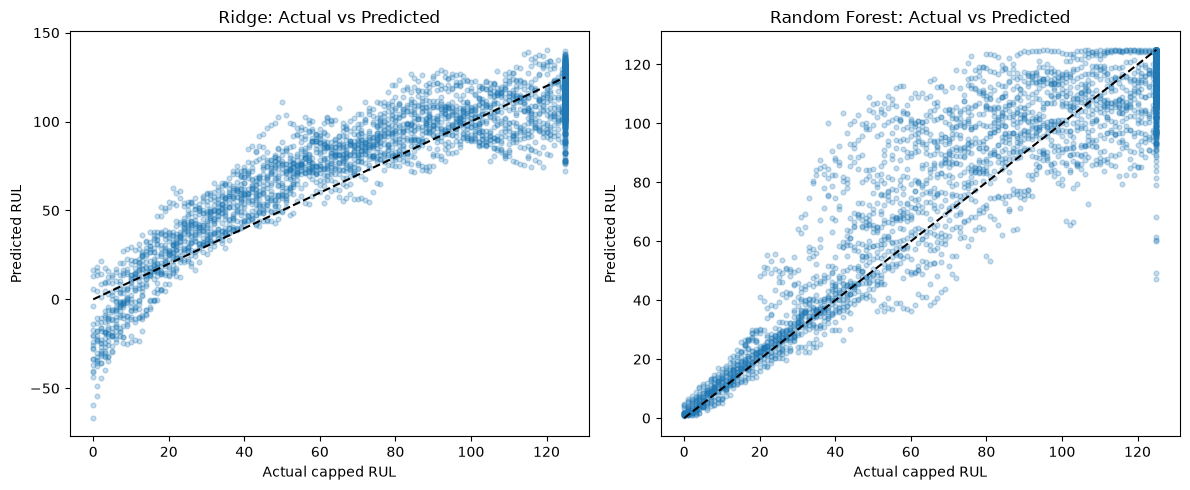

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_validation, ridge_validation_predictions, alpha=0.25, s=12)
axes[0].plot([0, 125], [0, 125], '--', color='black')
axes[0].set_title('Ridge: Actual vs Predicted')
axes[0].set_xlabel('Actual capped RUL')
axes[0].set_ylabel('Predicted RUL')
axes[1].scatter(y_validation, rf_validation_predictions, alpha=0.25, s=12)
axes[1].plot([0, 125], [0, 125], '--', color='black')
axes[1].set_title('Random Forest: Actual vs Predicted')
axes[1].set_xlabel('Actual capped RUL')
axes[1].set_ylabel('Predicted RUL')
plt.tight_layout()
plt.show()
metadata_summary = {'random_seed': RANDOM_SEED, 'target': 'RUL_capped', 'validation_metrics': baseline_metrics.to_dict(orient='records'), 'test_metrics': test_metrics.to_dict(orient='records'), 'feature_count': len(feature_columns)}
with (ARTIFACT_DIR / 'baseline_metadata.json').open('w', encoding='utf-8') as handle:
    json.dump(metadata_summary, handle, indent=2)